In [80]:
#importing necessary framework
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

In [37]:
#loading dataset
data = pd.read_csv("POP.CSV")

In [39]:
data.tail(12)

,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
316,NaN,NaN,NaN,NaN,NaN,NaN
317,NaN,NaN,NaN,NaN,NaN,NaN
318,NaN,NaN,NaN,NaN,NaN,NaN
319,NaN,NaN,NaN,NaN,NaN,NaN
320,NaN,NaN,NaN,NaN,NaN,NaN
321,NaN,NaN,NaN,NaN,NaN,NaN
322,NaN,NaN,NaN,NaN,NaN,NaN
323,NaN,NaN,NaN,NaN,NaN,NaN
324,NaN,NaN,NaN,NaN,NaN,NaN
325,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
data.shape

(328, 6)

In [41]:
data.dtypes

Unnamed: 0             str
Population 2022        str
Unnamed: 2         float64
Unnamed: 3             str
Unnamed: 4             str
Unnamed: 5             str
dtype: object

In [42]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       229 non-null    str    
 1   Population 2022  220 non-null    str    
 2   Unnamed: 2       0 non-null      float64
 3   Unnamed: 3       230 non-null    str    
 4   Unnamed: 4       230 non-null    str    
 5   Unnamed: 5       2 non-null      str    
dtypes: float64(1), str(5)
memory usage: 20.9 KB


In [43]:
data.columns 

Index(['Unnamed: 0', 'Population 2022', 'Unnamed: 2', 'Unnamed: 3',
       'Unnamed: 4', 'Unnamed: 5'],
      dtype='str')

In [44]:
data.isnull().sum()

Unnamed: 0          99
Population 2022    108
Unnamed: 2         328
Unnamed: 3          98
Unnamed: 4          98
Unnamed: 5         326
dtype: int64

In [45]:
data.duplicated().sum()

np.int64(95)

In [46]:
data[data.duplicated]

,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
1,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
221,NaN,NaN,NaN,NaN,NaN,NaN
222,NaN,NaN,NaN,NaN,NaN,NaN
224,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
323,NaN,NaN,NaN,NaN,NaN,NaN
324,NaN,NaN,NaN,NaN,NaN,NaN
325,NaN,NaN,NaN,NaN,NaN,NaN
326,NaN,NaN,NaN,NaN,NaN,NaN


In [47]:
data_clean= data.dropna()

In [58]:
data=data.drop(columns=['Unnamed: 2','Unnamed: 5'])

In [69]:
data = data.rename(columns={
    'Unnamed: 0':'Country_ID', 
    'Population 2022':'Ranking',
    'Unnamed: 3':'Country',
    'Unnamed: 4':'Economy'})

In [70]:
data.columns

Index(['Country_ID', 'Ranking', 'Country', 'Economy'], dtype='str')

In [71]:
data.head(10)

,Country_ID,Ranking,Country,Economy
0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,NaN,Ranking,Economy,(thousands)
3,NaN,NaN,NaN,NaN
4,IND,1,India,"1,417,173"
5,CHN,2,China,"1,412,175"
6,USA,3,United States,"333,288"
7,IDN,4,Indonesia,"275,501"
8,PAK,5,Pakistan,"235,825"
9,NGA,6,Nigeria,"218,541"


In [72]:
data=data.iloc[4:].reset_index(drop=True)

In [77]:
data=data.ffill()

In [88]:
data['Economy']=data['Economy'].astype(str).str.replace(',',',',regex=True)
data['Economy']=pd.to_numeric(data['Economy'],errors='coerce')

In [94]:
top_Countries = data.groupby('Country')['Economy'].last().nlargest(5).index


<Axes: xlabel='Country', ylabel='Economy'>

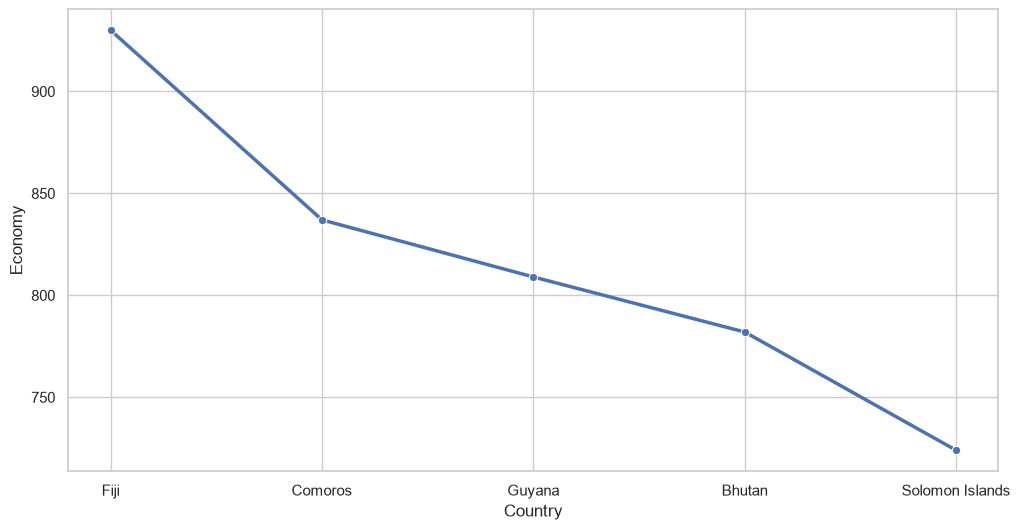

In [97]:
data_top5=data[data['Country'].isin(top_Countries)]
plt.figure(figsize=(12,6))
sns.lineplot(data=data_top5, x='Country',y='Economy',marker='o',linewidth=2.5)

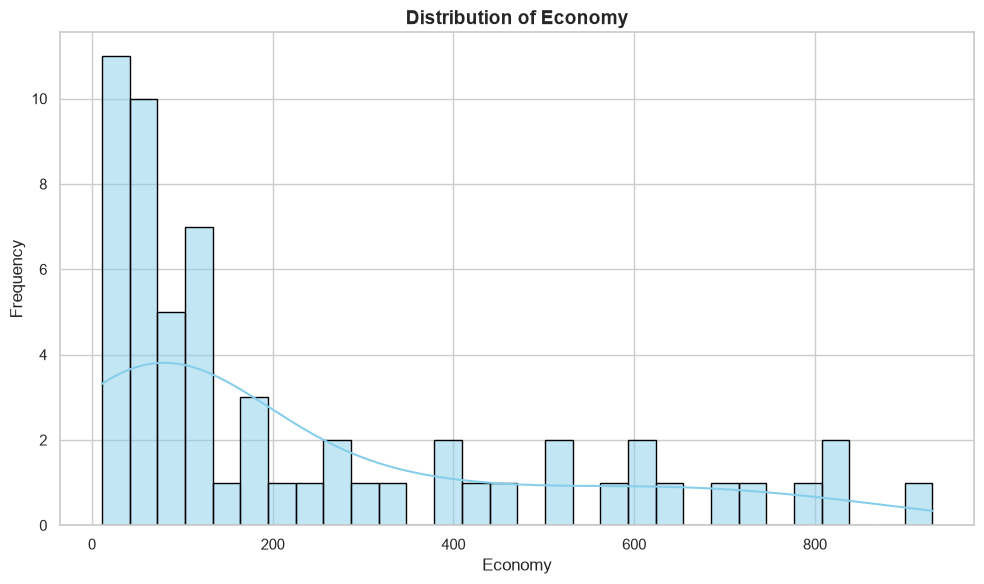

In [98]:
plt.figure(figsize=(10,6))
sns.histplot(data['Economy'],kde=True,bins=30,color='skyblue',edgecolor='black')
plt.title('Distribution of Economy',fontsize=14,fontweight='bold')
plt.xlabel('Economy',fontsize=12)
plt.ylabel('Frequency',fontsize=12)
plt.tight_layout()
plt.show()
           

In [ ]:
data

In [100]:
corr_matrix=data[['Ranking','Economy']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt='.2f',vmin=-1,vmax=1,linewidths=0.5)
plt.title('Correlation Heatmap:Ranking vs Economy',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

ValueError: could not convert string to float: 'a. Excludes Abkhazia and South Ossetia.  b. Excludes Transnistria.  '